In [ ]:
!pip install -q tensorflow opencv-python-headless scikit-learn matplotlib seaborn gradio

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import tensorflow as tf
import gradio as gr

from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPU: []


In [ ]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


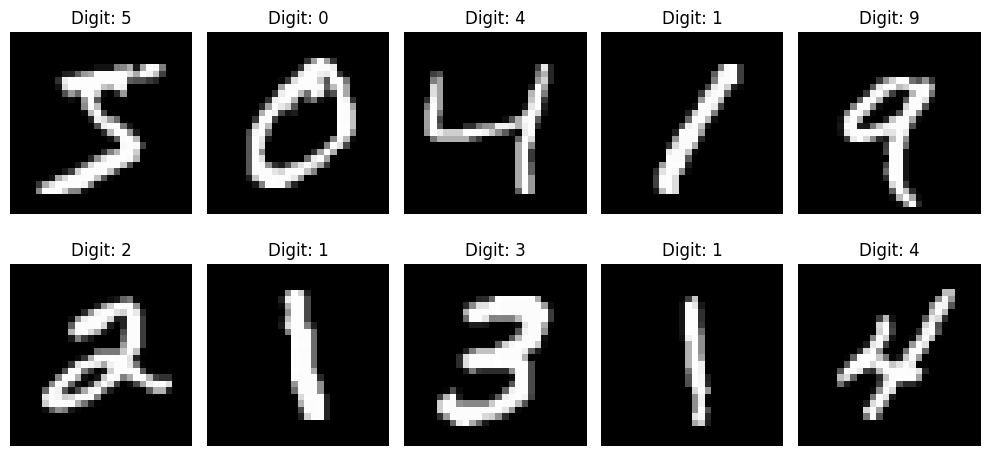

In [ ]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Digit: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Normalize pixel values
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Add channel dimension
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

Training shape: (60000, 28, 28, 1)
Testing shape: (10000, 28, 28, 1)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [ ]:
data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.10, 0.10)
])

print("Data augmentation created successfully!")

Data augmentation created successfully!


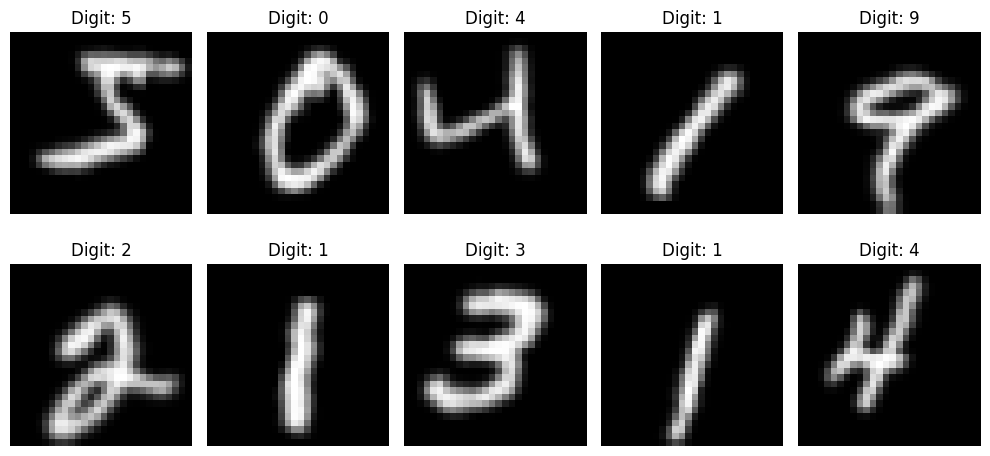

In [ ]:
plt.figure(figsize=(10, 5))

for i in range(10):
    augmented = data_augmentation(
        X_train[i:i+1],
        training=True
    )

    plt.subplot(2, 5, i + 1)
    plt.imshow(augmented[0, :, :, 0], cmap="gray")
    plt.title(f"Digit: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
model = models.Sequential([

    layers.Input(shape=(28, 28, 1)),

    data_augmentation,

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.BatchNormalization(),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 26, 26, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 11, 11, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 3, 3, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 242,442 (947.04 KB)

 Trainable params: 241,994 (945.29 KB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [ ]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

print("Callbacks ready!")

Callbacks ready!


In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 82s 97ms/step - accuracy: 0.9902 - loss: 0.0338 - val_accuracy: 0.9928 - val_loss: 0.0329 - learning_rate: 1.2500e-04
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 82s 97ms/step - accuracy: 0.9901 - loss: 0.0337 - val_accuracy: 0.9928 - val_loss: 0.0381 - learning_rate: 1.2500e-04
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 83s 98ms/step - accuracy: 0.9911 - loss: 0.0305 - val_accuracy: 0.9930 - val_loss: 0.0326 - learning_rate: 6.2500e-05


In [ ]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Test Loss:", round(test_loss, 4))

Test Accuracy: 99.28 %
Test Loss: 0.0232


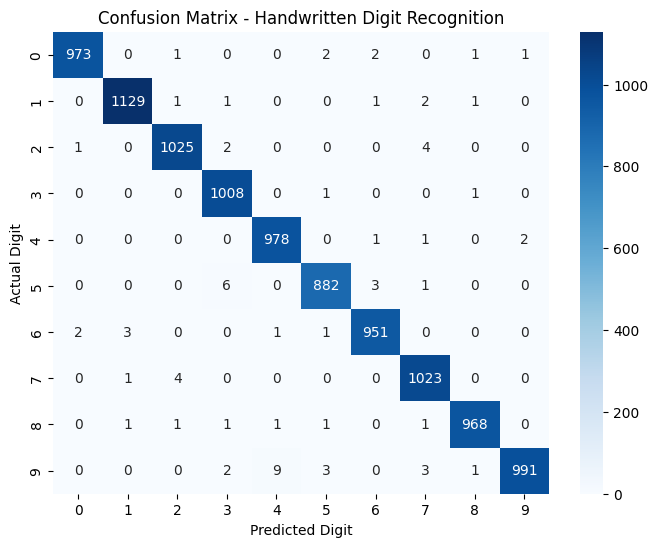

In [ ]:
y_pred = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred, axis=1)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Confusion Matrix - Handwritten Digit Recognition")
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.show()

In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99       980
           1       1.00      0.99      1.00      1135
           2       0.99      0.99      0.99      1032
           3       0.99      1.00      0.99      1010
           4       0.99      1.00      0.99       982
           5       0.99      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       0.99      1.00      0.99      1028
           8       1.00      0.99      0.99       974
           9       1.00      0.98      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



In [ ]:
model.save("handwritten_digit_recognition.keras")

print("Model saved successfully! ✅")

Model saved successfully! ✅


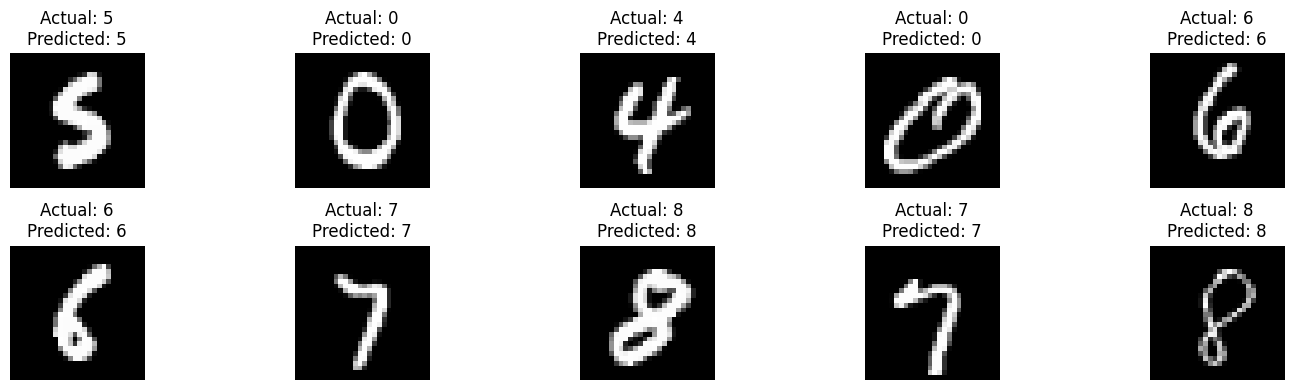

In [ ]:
indices = np.random.choice(len(X_test), 10, replace=False)

plt.figure(figsize=(15, 4))

for i, idx in enumerate(indices):
    prediction = np.argmax(model.predict(X_test[idx:idx+1], verbose=0))

    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[idx].squeeze(), cmap="gray")
    plt.title(f"Actual: {y_test[idx]}\nPredicted: {prediction}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
def predict_digit(image):
    image = np.array(image)

    # Convert to grayscale if needed
    if len(image.shape) == 3:
        image = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    # Resize to MNIST size
    image = cv2.resize(image, (28, 28))

    # Normalize
    image = image.astype("float32") / 255.0

    # Add required dimensions
    image = image.reshape(1, 28, 28, 1)

    # Prediction
    probabilities = model.predict(image, verbose=0)[0]
    digit = np.argmax(probabilities)
    confidence = probabilities[digit] * 100

    return digit, confidence


print("Prediction function ready! ✅")

Prediction function ready! ✅


In [ ]:
def preprocess_real_image(image):
    # Convert to grayscale
    if len(image.shape) == 3:
        gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    else:
        gray = image.copy()

    # Resize for easier processing
    h, w = gray.shape
    scale = 800 / max(h, w)

    if scale < 1:
        gray = cv2.resize(
            gray,
            (int(w * scale), int(h * scale))
        )

    # Remove horizontal notebook lines
    binary = cv2.adaptiveThreshold(
        gray,
        255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY_INV,
        31,
        10
    )

    horizontal_kernel = cv2.getStructuringElement(
        cv2.MORPH_RECT,
        (40, 1)
    )

    horizontal_lines = cv2.morphologyEx(
        binary,
        cv2.MORPH_OPEN,
        horizontal_kernel
    )

    digit = cv2.subtract(binary, horizontal_lines)

    # Remove tiny noise
    kernel = np.ones((2, 2), np.uint8)
    digit = cv2.morphologyEx(
        digit,
        cv2.MORPH_OPEN,
        kernel
    )

    # Find digit area
    contours, _ = cv2.findContours(
        digit,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    if not contours:
        return np.zeros((28, 28), dtype=np.float32)

    # Combine useful contours
    boxes = []

    for c in contours:
        x, y, cw, ch = cv2.boundingRect(c)
        area = cv2.contourArea(c)

        if area > 20 and cw > 3 and ch > 5:
            boxes.append((x, y, cw, ch))

    if not boxes:
        return np.zeros((28, 28), dtype=np.float32)

    x1 = min(x for x, y, cw, ch in boxes)
    y1 = min(y for x, y, cw, ch in boxes)
    x2 = max(x + cw for x, y, cw, ch in boxes)
    y2 = max(y + ch for x, y, cw, ch in boxes)

    # Add padding
    pad = 15
    x1 = max(0, x1 - pad)
    y1 = max(0, y1 - pad)
    x2 = min(digit.shape[1], x2 + pad)
    y2 = min(digit.shape[0], y2 + pad)

    cropped = digit[y1:y2, x1:x2]

    # Fit digit inside 20x20
    h, w = cropped.shape
    size = max(h, w)

    canvas = np.zeros((size, size), dtype=np.uint8)

    y_offset = (size - h) // 2
    x_offset = (size - w) // 2

    canvas[
        y_offset:y_offset+h,
        x_offset:x_offset+w
    ] = cropped

    resized = cv2.resize(
        canvas,
        (20, 20),
        interpolation=cv2.INTER_AREA
    )

    # Put inside 28x28 MNIST-style image
    final = np.zeros((28, 28), dtype=np.uint8)

    final[4:24, 4:24] = resized

    return final.astype("float32") / 255.0


print("Real-image preprocessing ready! ✅")

Real-image preprocessing ready! ✅


In [ ]:
def predict_real_digit(image):
    processed = preprocess_real_image(image)

    prediction = model.predict(
        processed.reshape(1, 28, 28, 1),
        verbose=0
    )[0]

    digit = np.argmax(prediction)
    confidence = prediction[digit] * 100

    return digit, confidence, processed


print("Real-image prediction system ready! ✅")

Real-image prediction system ready! ✅


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving '7.png'.jpeg to '7.png'.jpeg


Predicted Digit: 1
Confidence: 100.00%


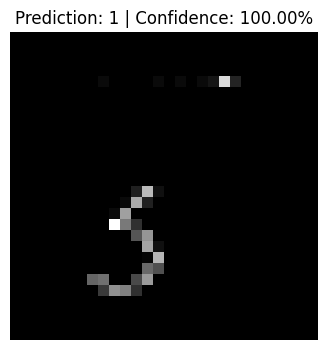

In [ ]:
filename = list(uploaded.keys())[0]

img = cv2.imread(filename)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

digit, confidence, processed = predict_real_digit(img)

print("Predicted Digit:", digit)
print("Confidence:", f"{confidence:.2f}%")

plt.figure(figsize=(4, 4))
plt.imshow(processed, cmap="gray")
plt.title(f"Prediction: {digit} | Confidence: {confidence:.2f}%")
plt.axis("off")
plt.show()

In [ ]:
from google.colab import files
import zipfile
import os

print("UPLOAD ONLY A .ZIP FILE CONTAINING YOUR HANDWRITTEN IMAGES")

uploaded = files.upload()

filename = list(uploaded.keys())[0]

print("Uploaded:", filename)

if not filename.lower().endswith(".zip"):
    print("❌ ERROR: This is not a ZIP file.")
    print("Please upload a .zip containing your images.")
else:
    if not zipfile.is_zipfile(filename):
        print("❌ ERROR: The file has .zip extension but is not a valid ZIP file.")
    else:
        extract_folder = "handwritten_10000"

        with zipfile.ZipFile(filename, "r") as zip_ref:
            zip_ref.extractall(extract_folder)

        print("✅ ZIP extracted successfully!")
        print("Folder:", extract_folder)

UPLOAD ONLY A .ZIP FILE CONTAINING YOUR HANDWRITTEN IMAGES


Saving '7.png'.jpeg to '7.png' (3).jpeg
Uploaded: '7.png' (3).jpeg
❌ ERROR: This is not a ZIP file.
Please upload a .zip containing your images.


Saving '7.png'.jpeg to '7.png' (4).jpeg
Using: '7.png' (4).jpeg
Predicted Digit: 1
Confidence: 100.00%


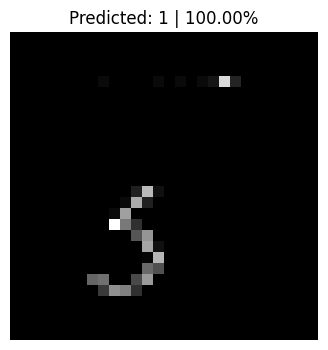

In [ ]:
from google.colab import files
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

uploaded = files.upload()

filename = next(iter(uploaded))
print("Using:", filename)

img = np.array(Image.open(filename).convert("RGB"))

digit, confidence, processed = predict_real_digit(img)

print("Predicted Digit:", digit)
print("Confidence:", f"{confidence:.2f}%")

plt.figure(figsize=(4,4))
plt.imshow(processed, cmap="gray")
plt.title(f"Predicted: {digit} | {confidence:.2f}%")
plt.axis("off")
plt.show()

In [ ]:
# Predict all 10,000 test images
predictions = model.predict(X_test, batch_size=128, verbose=1)

predicted_digits = np.argmax(predictions, axis=1)

accuracy = np.mean(predicted_digits == y_test)

print("Total test images:", len(X_test))
print("Correct predictions:", np.sum(predicted_digits == y_test))
print("Wrong predictions:", np.sum(predicted_digits != y_test))
print("Final Test Accuracy:", round(accuracy * 100, 2), "%")

79/79 ━━━━━━━━━━━━━━━━━━━━ 4s 55ms/step
Total test images: 10000
Correct predictions: 9928
Wrong predictions: 72
Final Test Accuracy: 99.28 %


In [ ]:
import gradio as gr
import numpy as np
import cv2

def predict_from_canvas(image):
    if image is None:
        return "Please draw a digit.", None

    # Gradio canvas may return RGBA/RGB
    if len(image.shape) == 3:
        gray = cv2.cvtColor(image, cv2.COLOR_RGBA2GRAY if image.shape[2] == 4 else cv2.COLOR_RGB2GRAY)
    else:
        gray = image

    # Invert if background is white
    if np.mean(gray) > 127:
        gray = 255 - gray

    # Find digit
    coords = cv2.findNonZero(gray)

    if coords is None:
        return "Please draw a digit.", None

    x, y, w, h = cv2.boundingRect(coords)

    # Crop + padding
    digit = gray[y:y+h, x:x+w]

    size = max(w, h)
    canvas = np.zeros((size, size), dtype=np.uint8)

    x_offset = (size - w) // 2
    y_offset = (size - h) // 2

    canvas[y_offset:y_offset+h, x_offset:x_offset+w] = digit

    # Resize to MNIST format
    canvas = cv2.resize(canvas, (28, 28))

    canvas = canvas.astype("float32") / 255.0

    # Predict
    probs = model.predict(
        canvas.reshape(1, 28, 28, 1),
        verbose=0
    )[0]

    digit_prediction = int(np.argmax(probs))
    confidence = float(np.max(probs) * 100)

    return (
        f"Predicted Digit: {digit_prediction}",
        f"Confidence: {confidence:.2f}%"
    )


with gr.Blocks(title="Handwritten Digit AI") as demo:

    gr.Markdown("""
    # 🔢 Handwritten Digit Recognition AI
    ### CNN-based handwritten digit classification
    Draw a digit from **0–9** in the canvas below.
    """)

    with gr.Row():

        with gr.Column():
            canvas = gr.Image(
                type="numpy",
                image_mode="L",
                sources=["upload"],
                label="Draw / Upload Digit"
            )

        with gr.Column():
            prediction = gr.Textbox(
                label="Prediction"
            )

            confidence = gr.Textbox(
                label="Model Confidence"
            )

    button = gr.Button("🚀 Recognize Digit")

    button.click(
        predict_from_canvas,
        inputs=canvas,
        outputs=[prediction, confidence]
    )

    gr.Markdown("""
    ---
    **Model:** Convolutional Neural Network (CNN)
    **Dataset:** MNIST
    **Training Images:** 60,000
    **Test Images:** 10,000
    """)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5de915602e2ea08252.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


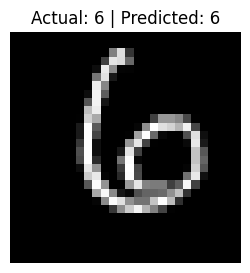

Actual digit: 6
Predicted digit: 6
Confidence: 100.00%


In [ ]:
# FINAL MODEL SANITY CHECK

idx = 100

image = X_test[idx]
actual = y_test[idx]

prob = model.predict(
    image.reshape(1, 28, 28, 1),
    verbose=0
)[0]

predicted = np.argmax(prob)

plt.figure(figsize=(3,3))
plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Actual: {actual} | Predicted: {predicted}")
plt.axis("off")
plt.show()

print("Actual digit:", actual)
print("Predicted digit:", predicted)
print("Confidence:", f"{prob[predicted]*100:.2f}%")

In [ ]:
import gradio as gr
import numpy as np
import cv2

def predict_digit(image):
    if image is None:
        return "Draw a digit first!", 0

    # Gradio canvas/image → grayscale
    if image.ndim == 3:
        gray = cv2.cvtColor(image, cv2.COLOR_RGBA2GRAY
                            if image.shape[2] == 4
                            else cv2.COLOR_RGB2GRAY)
    else:
        gray = image

    # Make digit white on black, like MNIST
    if gray.mean() > 127:
        gray = 255 - gray

    # Remove tiny noise
    _, binary = cv2.threshold(gray, 30, 255, cv2.THRESH_BINARY)

    # Find digit
    points = cv2.findNonZero(binary)

    if points is None:
        return "Draw a digit first!", 0

    x, y, w, h = cv2.boundingRect(points)
    digit = binary[y:y+h, x:x+w]

    # Keep aspect ratio + center
    size = max(w, h) + 20
    square = np.zeros((size, size), dtype=np.uint8)

    xoff = (size - w) // 2
    yoff = (size - h) // 2

    square[yoff:yoff+h, xoff:xoff+w] = digit

    # MNIST size
    final = cv2.resize(square, (28, 28))
    final = final.astype("float32") / 255.0

    # Predict
    probs = model.predict(
        final.reshape(1, 28, 28, 1),
        verbose=0
    )[0]

    pred = int(np.argmax(probs))
    confidence = float(probs[pred] * 100)

    return f"Predicted Digit: {pred}", f"{confidence:.2f}%"

demo = gr.Interface(
    fn=predict_digit,
    inputs=gr.Image(
        type="numpy",
        image_mode="L",
        label="Upload a clear digit image"
    ),
    outputs=[
        gr.Textbox(label="Prediction"),
        gr.Textbox(label="Confidence")
    ],
    title="Handwritten Digit Recognition",
    description="Upload a single handwritten digit (0–9)."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c690342abd09b6486d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import gradio as gr
import numpy as np
import cv2

def preprocess_handwriting(image):

    # Convert to grayscale
    if image.ndim == 3:
        gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    else:
        gray = image.copy()

    # Improve contrast
    gray = cv2.GaussianBlur(gray, (3, 3), 0)

    # Adaptive threshold for pencil handwriting
    binary = cv2.adaptiveThreshold(
        gray,
        255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY_INV,
        31,
        9
    )

    # Detect and remove notebook horizontal lines
    kernel = cv2.getStructuringElement(
        cv2.MORPH_RECT,
        (max(25, gray.shape[1] // 8), 1)
    )

    horizontal = cv2.morphologyEx(
        binary,
        cv2.MORPH_OPEN,
        kernel
    )

    clean = cv2.subtract(binary, horizontal)

    # Remove small noise
    clean = cv2.morphologyEx(
        clean,
        cv2.MORPH_OPEN,
        np.ones((2, 2), np.uint8)
    )

    # Find connected components
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
        clean,
        8
    )

    components = []

    for i in range(1, num_labels):
        x, y, w, h, area = stats[i]

        if area > 30 and h > 10:
            components.append((x, y, w, h, area))

    if not components:
        return np.zeros((28, 28), dtype=np.float32)

    # Bounding box around handwriting
    x1 = min(c[0] for c in components)
    y1 = min(c[1] for c in components)

    x2 = max(c[0] + c[2] for c in components)
    y2 = max(c[1] + c[3] for c in components)

    # Padding
    pad = 15

    x1 = max(0, x1 - pad)
    y1 = max(0, y1 - pad)
    x2 = min(clean.shape[1], x2 + pad)
    y2 = min(clean.shape[0], y2 + pad)

    digit = clean[y1:y2, x1:x2]

    # Make square
    h, w = digit.shape
    size = max(h, w)

    square = np.zeros((size, size), dtype=np.uint8)

    xoff = (size - w) // 2
    yoff = (size - h) // 2

    square[yoff:yoff+h, xoff:xoff+w] = digit

    # Resize to MNIST
    digit28 = cv2.resize(
        square,
        (28, 28),
        interpolation=cv2.INTER_AREA
    )

    return digit28.astype("float32") / 255.0


def recognize(image):

    if image is None:
        return "Upload an image", 0, None

    processed = preprocess_handwriting(image)

    probabilities = model.predict(
        processed.reshape(1, 28, 28, 1),
        verbose=0
    )[0]

    predicted = int(np.argmax(probabilities))
    confidence = float(np.max(probabilities) * 100)

    return (
        f"Predicted Digit: {predicted}",
        f"{confidence:.2f}%",
        processed
    )


with gr.Blocks() as demo:

    gr.Markdown(
        "# 🔢 AI Handwritten Digit Recognition"
    )

    with gr.Row():

        with gr.Column():
            input_image = gr.Image(
                type="numpy",
                label="Upload Handwritten Digit"
            )

        with gr.Column():
            prediction = gr.Textbox(
                label="Prediction"
            )

            confidence = gr.Textbox(
                label="Confidence"
            )

            processed = gr.Image(
                label="What the AI Actually Sees"
            )

    button = gr.Button("🔍 Recognize Digit")

    button.click(
        recognize,
        inputs=input_image,
        outputs=[
            prediction,
            confidence,
            processed
        ]
    )

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://004b100640af74f0f6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
